# 02 · Train — Fine-tune a pretrained CNN for nodule/mass detection

**This notebook:**
1. Loads the patient-level splits saved by `01_data_exploration`
2. Builds the image pipeline (resizing, normalisation, light augmentation for training)
3. Fine-tunes an ImageNet-pretrained CNN (DenseNet-121 by default) on the Mac GPU (MPS)
4. Tracks validation AUC each epoch and keeps the best checkpoint
5. Picks a decision threshold on the validation set for a target sensitivity

**Inputs:** `data/splits/train.csv`, `data/splits/val.csv`, `data/images/`
**Outputs:** `checkpoints/<RUN_NAME>_best.pt` (weights, config and threshold), `checkpoints/<RUN_NAME>_history.csv`

The **test split is not used here**. It is touched once, in `03_evaluate.ipynb`, so the reported test numbers are not tuned on.

## 0. Google Colab setup (skipped on your own computer)

To train on a free Colab GPU instead of your Mac:
1. Run `00_colab_prepare_data.ipynb` once. It saves the images to Google Drive.
2. In Colab, pick **Runtime → Change runtime type → T4 GPU**, then run this notebook from the top.

This cell connects Google Drive, clones the repository, and unpacks the images onto the Colab machine. Checkpoints and reports are written to `MyDrive/chest_xray_classifier/` so they outlast the session. On your own computer it does nothing.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DRIVE_DIR = Path("/content/drive/MyDrive/chest_xray_classifier")   # images archive, checkpoints, reports

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    repo = Path("/content/chest_xray_classifier")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/vutr2/chest_xray_classifier.git", str(repo)], check=True)
    if not (repo / "data" / "images").exists():
        print("Unpacking images from Google Drive (a few minutes)...")
        subprocess.run(["tar", "-xf", str(DRIVE_DIR / "images_512.tar"), "-C", str(repo / "data")], check=True)
    os.chdir(repo / "notebooks")

    import torch
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none: Runtime > Change runtime type > T4 GPU"
    print(f"Colab ready | {len(os.listdir(repo / 'data' / 'images'))} images | GPU: {gpu}")

Mounted at /content/drive
Unpacking images from Google Drive (a few minutes)...
Colab ready | 44828 images | GPU: Tesla T4


## 1. Configuration

In [2]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repo root
DATA_DIR = ROOT / "data"
IMAGE_DIR = DATA_DIR / "images"
SPLIT_DIR = DATA_DIR / "splits"
CKPT_DIR = DRIVE_DIR / "checkpoints" if IN_COLAB else ROOT / "checkpoints"   # git-ignored locally
CKPT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "densenet121"   # or "resnet50"
RUN_NAME = "densenet121_reg" # files are saved under this name: use a new name for each experiment
IMG_SIZE =   224             # input size the pretrained models were trained on
BATCH_SIZE = 32
EPOCHS = 15
LR = 3e-5                    # lower: the pretrained weights change more gently, so memorising is slower
WEIGHT_DECAY = 1e-2          # AdamW's default: keeps weights small, a brake on memorising
PATIENCE = 4                 # stop early if val AUC hasn't improved for this many epochs
TARGET_SENSITIVITY = 0.90    # used to pick the decision threshold on validation
NUM_WORKERS = 2 if IN_COLAB else 0   # 0 in a notebook on macOS (see section 4); Colab's Linux can use 2
SEED = 42

CKPT_PATH = CKPT_DIR / f"{RUN_NAME}_best.pt"

## 2. Device and reproducibility

In [3]:
import random

import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PyTorch 2.14.1+cu130 | device: cuda


## 3. Load the splits

In [4]:
import pandas as pd

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")

for name, d in [("train", train_df), ("val", val_df)]:
    print(f"{name:5s}: {len(d):5d} images | {d['Patient ID'].nunique():5d} patients "
          f"| positive rate {d['label'].mean():.1%}")

missing = [f for f in pd.concat([train_df, val_df])["Image Index"] if not (IMAGE_DIR / f).exists()]
assert not missing, f"{len(missing)} images listed in the splits are missing from {IMAGE_DIR}"

train: 31055 images | 13608 patients | positive rate 25.2%
val  :  6807 images |  2916 patients | positive rate 23.8%


## 4. Image pipeline and data loaders

The X-rays are 1024×1024 grayscale PNGs. The pretrained models expect 3-channel 224×224 images normalised with ImageNet statistics, so each image is converted to RGB (the grey value copied into all three channels), resized and normalised.

- **Training** images get random augmentation (crops, rotations up to 10°, small shifts, brightness/contrast changes), so the model never sees exactly the same image twice. This is the main defence against overfitting. There is no horizontal flip: it would put the heart on the wrong side, an anatomically unrealistic image.
- **Validation** images are only resized and normalised, so scores are comparable between epochs.

`NUM_WORKERS = 0` loads images in the main process. On macOS, data-loader worker processes can't import classes defined inside a notebook, so higher values fail unless the dataset class is moved into a `.py` file.

In [5]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2 as T

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class ChestXrayDataset(Dataset):
    def __init__(self, df, image_dir, transform):
        self.files = df["Image Index"].tolist()
        self.labels = df["label"].astype("float32").tolist()
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.image_dir / self.files[i]).convert("RGB")
        return self.transform(img), torch.tensor(self.labels[i])


train_loader = DataLoader(ChestXrayDataset(train_df, IMAGE_DIR, train_tf),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(ChestXrayDataset(val_df, IMAGE_DIR, eval_tf),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), x.dtype, "| first labels:", y[:8].tolist())

Batch: (32, 3, 224, 224) torch.float32 | first labels: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]


Sanity check: what the model actually sees after augmentation (undoing the normalisation for display).

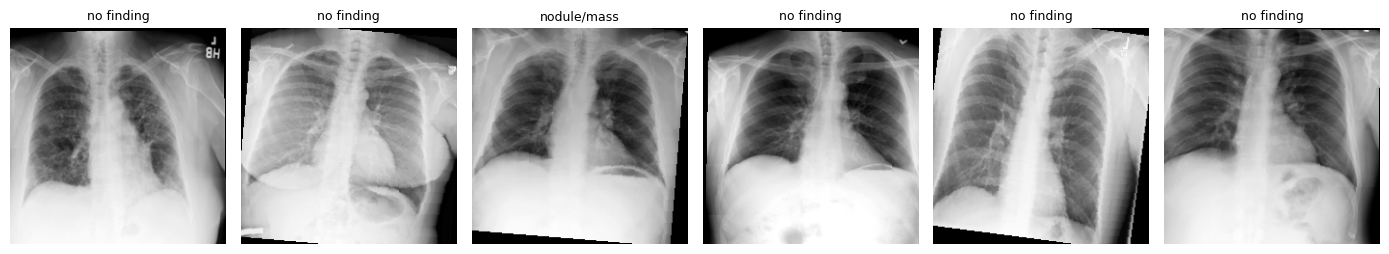

In [6]:
import matplotlib.pyplot as plt

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, img, label in zip(axes, x, y):
    ax.imshow((img * std + mean).clamp(0, 1)[0], cmap="gray")
    ax.set_title("nodule/mass" if label == 1 else "no finding", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Model

Start from a CNN pretrained on ImageNet and replace its last layer with a single output: one logit for "nodule/mass". DenseNet-121 is the backbone CheXNet (Rajpurkar et al., 2017) used on this same dataset; ResNet-50 is a common alternative. The first run downloads the pretrained weights (about 30 MB for DenseNet-121, 100 MB for ResNet-50).

In [7]:
import torch.nn as nn
from torchvision import models


def build_model(name):
    if name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, 1)
    elif name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 1)
    else:
        raise ValueError(f"Unknown model: {name}")
    return model


model = build_model(MODEL_NAME).to(device)
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 175MB/s]


densenet121: 7.0M parameters


## 6. Loss, optimiser and learning-rate schedule

- **Loss:** `BCEWithLogitsLoss` with `pos_weight` = negatives ÷ positives in the training set (about 3), so positives and negatives contribute equally to the loss despite the 1 : 3 imbalance.
- **Optimiser:** AdamW with a small learning rate, since the pretrained weights only need adjusting.
- **Schedule:** cosine decay of the learning rate over `EPOCHS`.

In [8]:
n_pos = int(train_df["label"].sum())
n_neg = len(train_df) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], device=device)
print(f"pos_weight = {pos_weight.item():.2f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

pos_weight = 2.97


## 7. Training and evaluation functions

In [9]:
from sklearn.metrics import roc_auc_score


def train_one_epoch(model, loader):
    """One pass over the training set. Returns the mean loss."""
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x).squeeze(1), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def predict(model, loader):
    """Returns the mean loss, predicted probabilities and true labels."""
    model.eval()
    total_loss, probs, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x).squeeze(1)
        total_loss += criterion(logits, y).item() * len(y)
        probs.append(torch.sigmoid(logits).cpu())
        labels.append(y.cpu())
    return total_loss / len(loader.dataset), torch.cat(probs).numpy(), torch.cat(labels).numpy()

## 8. Train

Each epoch is one pass over the training set followed by validation loss and AUC. The checkpoint with the best validation AUC is saved; training stops early if validation AUC hasn't improved for `PATIENCE` epochs. Expect a few minutes per epoch.

In [10]:
import time

history = []
best_auc, epochs_without_improvement = 0.0, 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader)
    val_loss, val_probs, val_labels = predict(model, val_loader)
    val_auc = float(roc_auc_score(val_labels, val_probs))
    scheduler.step()

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auc": val_auc})
    improved = val_auc > best_auc
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} "
          f"| val AUC {val_auc:.4f} | {time.time() - start:.0f}s" + ("  <- best" if improved else ""))

    if improved:
        best_auc, epochs_without_improvement = val_auc, 0
        torch.save({
            "run_name": RUN_NAME,
            "model_name": MODEL_NAME,
            "lr": LR,
            "weight_decay": WEIGHT_DECAY,
            "img_size": IMG_SIZE,
            "epoch": epoch,
            "val_auc": val_auc,
            "state_dict": model.state_dict(),
        }, CKPT_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Stopping early: no improvement for {PATIENCE} epochs")
            break

print(f"Best val AUC: {best_auc:.4f} -> saved to {CKPT_PATH}")

Epoch  1/15 | train loss 0.8918 | val loss 0.8145 | val AUC 0.7886 | 480s  <- best
Epoch  2/15 | train loss 0.8105 | val loss 0.7782 | val AUC 0.8136 | 466s  <- best
Epoch  3/15 | train loss 0.7661 | val loss 0.7621 | val AUC 0.8202 | 446s  <- best
Epoch  4/15 | train loss 0.7324 | val loss 0.7733 | val AUC 0.8233 | 446s  <- best
Epoch  5/15 | train loss 0.6953 | val loss 0.7583 | val AUC 0.8262 | 447s  <- best
Epoch  6/15 | train loss 0.6567 | val loss 0.8036 | val AUC 0.8197 | 454s
Epoch  7/15 | train loss 0.6184 | val loss 0.8178 | val AUC 0.8110 | 451s
Epoch  8/15 | train loss 0.5693 | val loss 0.8538 | val AUC 0.8121 | 448s
Epoch  9/15 | train loss 0.5310 | val loss 0.9588 | val AUC 0.8125 | 444s
Stopping early: no improvement for 4 epochs
Best val AUC: 0.8262 -> saved to /content/drive/MyDrive/chest_xray_classifier/checkpoints/densenet121_reg_best.pt


## 9. Learning curves

If validation loss rises while training loss keeps falling, the model is starting to memorise the training set (overfitting). The saved checkpoint is from the best-AUC epoch, not the last one.

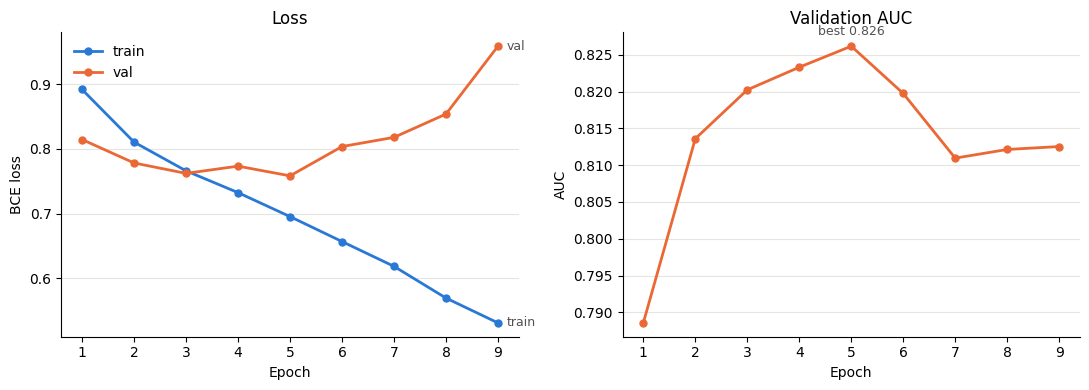

In [11]:
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"

hist = pd.DataFrame(history).set_index("epoch")
hist.to_csv(CKPT_DIR / f"{RUN_NAME}_history.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for col, color, name in [("train_loss", TRAIN_COLOR, "train"), ("val_loss", VAL_COLOR, "val")]:
    ax1.plot(hist.index, hist[col], color=color, lw=2, marker="o", ms=5, label=name)
    ax1.annotate(name, (hist.index[-1], hist[col].iloc[-1]), xytext=(6, 0),
                 textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax1.set(title="Loss", xlabel="Epoch", ylabel="BCE loss")
ax1.legend(frameon=False)

ax2.plot(hist.index, hist["val_auc"], color=VAL_COLOR, lw=2, marker="o", ms=5)
best = hist["val_auc"].idxmax()
ax2.annotate(f"best {hist.loc[best, 'val_auc']:.3f}", (best, hist.loc[best, "val_auc"]),
             xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
ax2.set(title="Validation AUC", xlabel="Epoch", ylabel="AUC")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", lw=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 10. Pick a decision threshold on validation

The model outputs a probability. To report sensitivity (the share of nodules/masses caught) we need a cut-off above which an X-ray is flagged. We pick it on the **validation** set as the highest threshold that still reaches `TARGET_SENSITIVITY`, and store it in the checkpoint so `03_evaluate.ipynb` applies the same cut-off to the test set.

In [12]:
from sklearn.metrics import roc_curve

ckpt = torch.load(CKPT_PATH, map_location="cpu")
model.load_state_dict(ckpt["state_dict"])

_, val_probs, val_labels = predict(model, val_loader)
fpr, tpr, thresholds = roc_curve(val_labels, val_probs, drop_intermediate=False)
i = int(np.argmax(tpr >= TARGET_SENSITIVITY))   # first (= highest) threshold reaching the target
threshold = float(thresholds[i])

print(f"Best epoch: {ckpt['epoch']} | val AUC {ckpt['val_auc']:.4f}")
print(f"Threshold {threshold:.3f} -> val sensitivity {tpr[i]:.1%}, specificity {1 - fpr[i]:.1%}")

ckpt["threshold"] = threshold
ckpt["target_sensitivity"] = TARGET_SENSITIVITY
torch.save(ckpt, CKPT_PATH)

Best epoch: 5 | val AUC 0.8262
Threshold 0.209 -> val sensitivity 90.0%, specificity 48.5%


## 11. Compare runs

Each run saves its own checkpoint and history under `RUN_NAME`, so earlier runs are kept (the first full-data run is `densenet121`). Pick the run with the highest **validation** AUC and point `CKPT_PATH` in `03_evaluate.ipynb` at its checkpoint. Never pick by test results.

In [13]:
rows = []
for path in sorted(CKPT_DIR.glob("*_history.csv")):
    h = pd.read_csv(path)
    best = h.loc[h["val_auc"].idxmax()]
    rows.append({"run": path.name.removesuffix("_history.csv"), "best val AUC": best["val_auc"],
                 "best epoch": int(best["epoch"]), "epochs run": len(h),
                 "train loss at best": best["train_loss"], "val loss at best": best["val_loss"]})

(pd.DataFrame(rows).set_index("run").sort_values("best val AUC", ascending=False)
   .style.format({"best val AUC": "{:.4f}", "train loss at best": "{:.3f}", "val loss at best": "{:.3f}"}))

,best val AUC,best epoch,epochs run,train loss at best,val loss at best
run,,,,,
densenet121_reg,0.8262,5,9,0.695,0.758


## Summary

- Fine-tuned an ImageNet-pretrained CNN on the patient-level training split, keeping the epoch with the best validation AUC.
- Chose a decision threshold on validation for the target sensitivity and saved it with the weights in `checkpoints/`.
- The test split has not been used yet.

**Next:** `03_evaluate.ipynb` loads the checkpoint, reports AUC-ROC, sensitivity and specificity on the test set at the saved threshold, and uses Grad-CAM to show which image regions drove the predictions.